In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [4]:
def w_norm_per_xbin(h,x,y):
    w = np.empty([len(x)-1,len(y)-1])
    for i in range(0,len(x)-1):
        for j in range(0,len(y)-1):
            w[i][j] = h[i][j]/sum(h[i]) + 10**-50
    return w

In [5]:
import math
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- Numpy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [18]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df9 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_10pthat11_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [43]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
w9=(float)(df9.iloc[df9.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df9['w']=np.ones(df9.shape[0])*w9
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8,df9])
df_herwig = df[['pt','b_ch','w','y1_ch','y2_ch','phi1_ch','phi2_ch','pts','bs_ch','y1s_ch','y2s_ch','phi1s_ch','phi2s_ch','b','bs']]

In [79]:
#df_match = applyCut(df_herwig, 'pts > 10 and pt > 5')
df = pd.read_csv('herwig.csv')
df_match = applyCut(df, 'distance1 < 0.02 and distance2 < 0.02')

In [80]:
df_match.eval('dpt_pt = (pts-pt)/pt', inplace=True)

In [81]:
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)] ]

In [82]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)] ]

separate opposite sign and same sign pairs by looking at the charged jet only

detector-level pT bin: 0


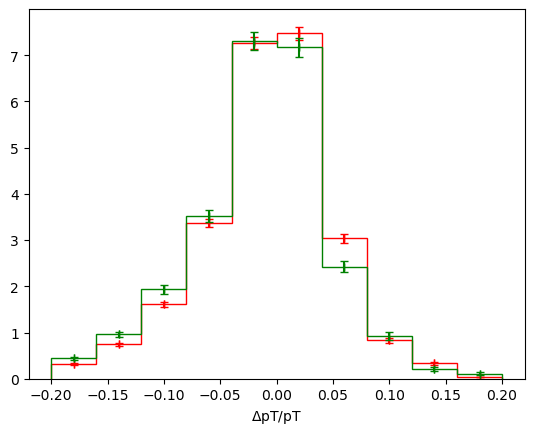

detector-level pT bin: 1


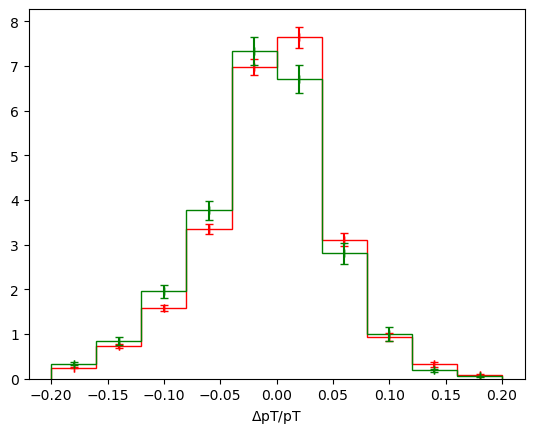

detector-level pT bin: 2


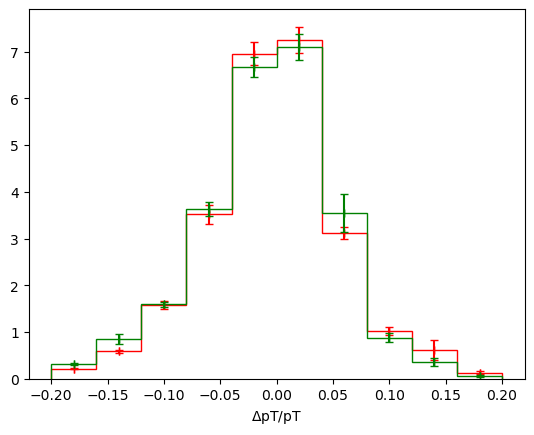

detector-level pT bin: 3


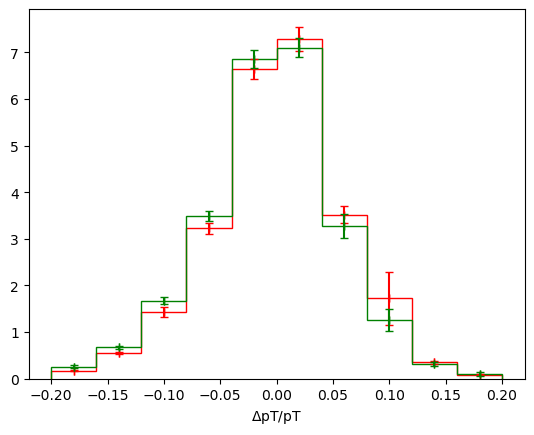

In [88]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs_ch==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs_ch==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)
    y_temp_os, yerr_temp_os, x = calc_hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    y_temp_ss, yerr_temp_ss, x = calc_hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], bins=np.arange(-0.2, 0.24, 0.04), density=True)
    print('detector-level pT bin:', i)
    plt.hist(df_temp_os['dpt_pt'], weights=df_temp_os['w'], color='r', histtype='step', range=(-0.2,0.2), density=True)
    plt.hist(df_temp_ss['dpt_pt'], weights=df_temp_ss['w'], color='g', histtype='step', range=(-0.2,0.2), density=True)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_os/sum(y_temp_os), xerr=0, yerr=25*yerr_temp_os/sum(y_temp_os), color='r',ls='none',capsize=3)
    plt.errorbar(np.arange(-0.18, 0.22, 0.04), 25*y_temp_ss/sum(y_temp_ss), xerr=0, yerr=25*yerr_temp_ss/sum(y_temp_ss), color='g',ls='none',capsize=3)
    plt.xlabel('$\Delta$pT/pT')
    plt.ylim(bottom=0)
    plt.show()

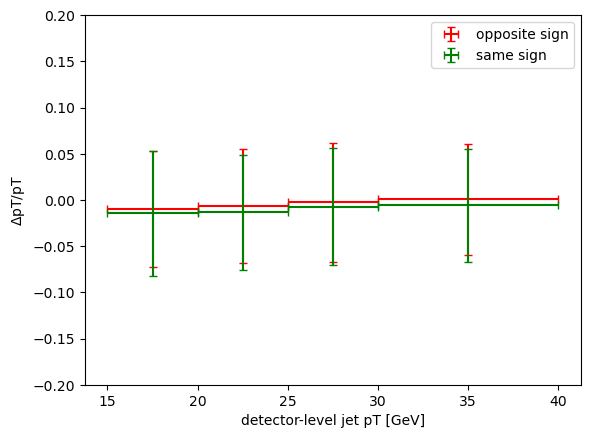

In [84]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [85]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs_ch==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs_ch==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)    

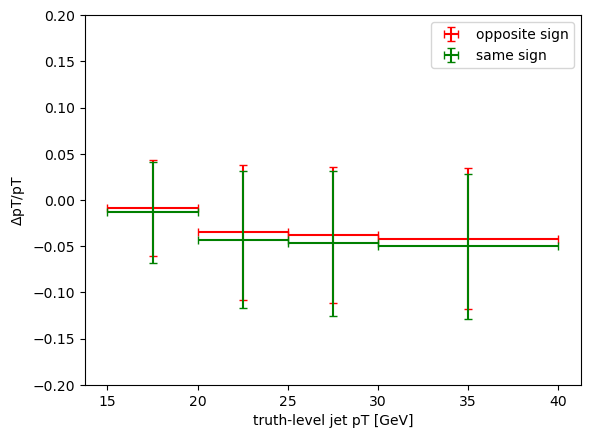

In [86]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

separate opposite sign and same sign pairs by looking at the full jet constituents

In [52]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pts_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pts_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)    

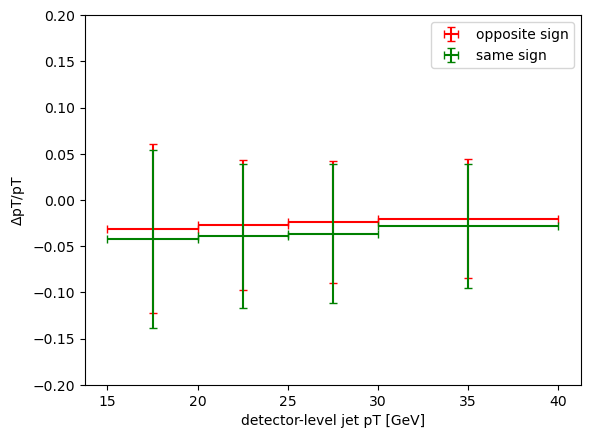

In [53]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('detector-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [54]:
dpt_pt_array_os = []
sigma_dpt_pt_array_os = []
dpt_pt_array_ss = []
sigma_dpt_pt_array_ss = []
for i in range(0,4):
    df_temp_os = applyCut(df_match_pt_array[i], 'bs==-1')
    df_temp_ss = applyCut(df_match_pt_array[i], 'bs==1')
    dpt_pt_os, sigma_dpt_pt_os = weighted_avg_and_std(df_temp_os['dpt_pt'], df_temp_os['w'])
    dpt_pt_ss, sigma_dpt_pt_ss = weighted_avg_and_std(df_temp_ss['dpt_pt'], df_temp_ss['w'])
    dpt_pt_array_os.append(dpt_pt_os)
    sigma_dpt_pt_array_os.append(sigma_dpt_pt_os)
    dpt_pt_array_ss.append(dpt_pt_ss)
    sigma_dpt_pt_array_ss.append(sigma_dpt_pt_ss)    

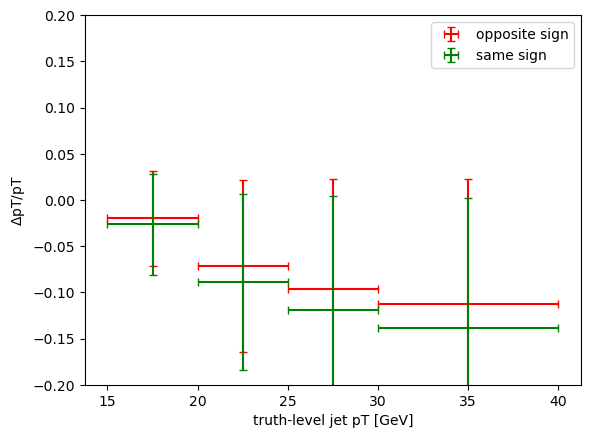

In [55]:
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_os, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_os, color='r', label='opposite sign', ls='none', capsize=3)
plt.errorbar([17.5, 22.5, 27.5, 35], dpt_pt_array_ss, xerr=[2.5, 2.5, 2.5, 5], yerr=sigma_dpt_pt_array_ss, color='g', label='same sign', ls='none', capsize=3)
plt.xlabel('truth-level jet pT [GeV]')
plt.ylabel('$\Delta$pT/pT')
plt.ylim(-0.2,0.2)
plt.legend()

In [17]:
h,x,y = np.histogram2d(df_match['pt'],df_match['pts'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

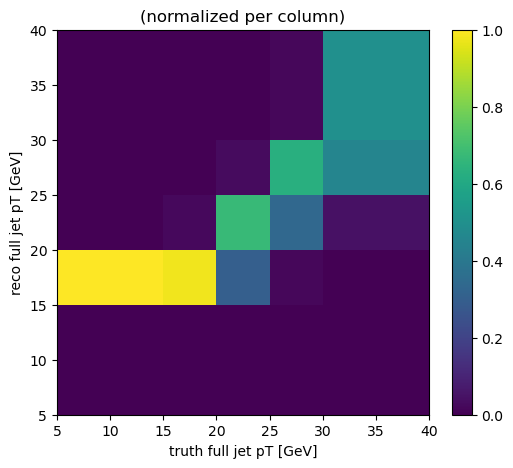

In [18]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('truth full jet pT [GeV]')
plt.ylabel('reco full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [19]:
h,x,y = np.histogram2d(df_match['pts'],df_match['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


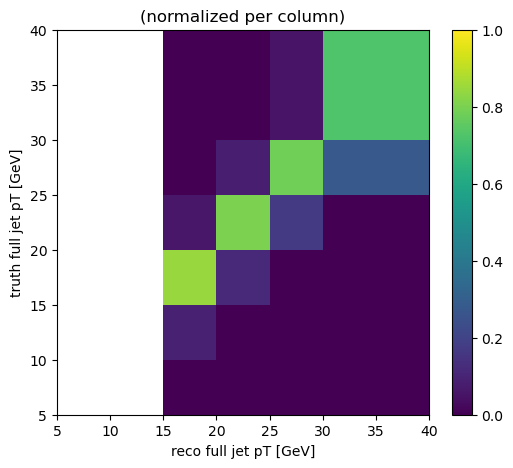

In [20]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

separate response matrices for opposite and same sign pairs 

In [21]:
h,x,y = np.histogram2d(df_match[df_match.bs_ch==-1]['pts'],df_match[df_match.bs_ch==-1]['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match[df_match.bs_ch==-1]['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


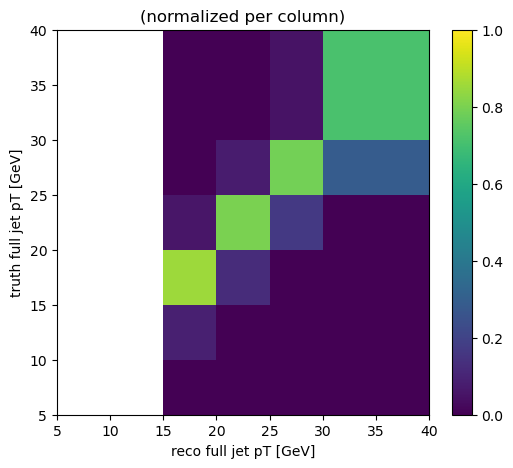

In [22]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)

In [23]:
h,x,y = np.histogram2d(df_match[df_match.bs_ch==+1]['pts'],df_match[df_match.bs_ch==+1]['pt'], bins=([5,10,15,20,25,30,40]), weights=df_match[df_match.bs_ch==+1]['w'], density=True)

/tmp/ipykernel_17182/2021765472.py:5: RuntimeWarning: invalid value encountered in scalar divide
  w[i][j] = h[i][j]/sum(h[i]) + 10**-50


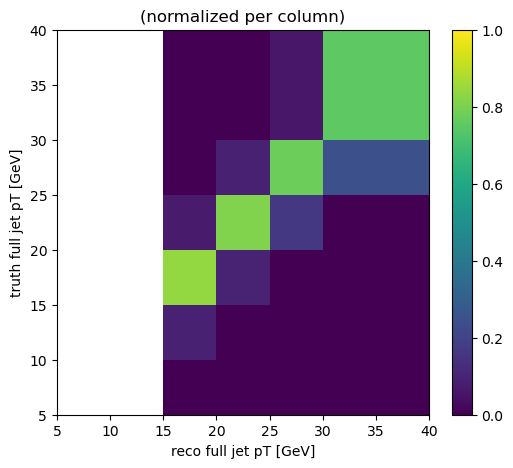

In [24]:
plt.figure(figsize=(6,5))
w = w_norm_per_xbin(h,[5,10,15,20,25,30,40],[5,10,15,20,25,30,40])
plt.pcolormesh([5,10,15,20,25,30,40],[5,10,15,20,25,30,40], np.transpose(w))
plt.xlabel('reco full jet pT [GeV]')
plt.ylabel('truth full jet pT [GeV]')
plt.title('(normalized per column)')
plt.colorbar()
plt.xlim(5,40)
plt.ylim(5,40)
plt.clim(0,1)